# 05 — Camera imbalance, sensitivity analysis and comparison of calibration gains
**Run after notebook 04**, beside notebooks 01–04 in `ml_project_final`, using the existing `ml` kernel. No retraining, image downloads, model loading, or new test forward passes are needed. This notebook reads the frozen test logits and decisions saved by notebook04. It writes a separate audit directory and never overwrites the original evaluation.

**Why this notebook is needed:** the proposal asks whether two classifiers' confidence can be calibrated at unseen camera locations. Camera separation prevents direct location leakage, but unequal event counts can let a few locations dominate fitting and evaluation. We examine camera representation, per-camera behaviour, equal-camera summaries, and a direct paired comparison of calibration gains.

This audit was specified **after examining the test results and finding camera imbalance**. It is a transparent post hoc sensitivity analysis, not a new untouched test, preregistered analysis, or remedy for concentrated calibration/policy data. Models, temperatures and acceptance thresholds remain fixed. Findings must be reported alongside notebook04, without choosing whichever weighting gives the preferred conclusion.


## 1. Setup and analysis choices
We use the same 15-bin ECE and 2,000 camera-bootstrap replicates as notebook04. NLL is the primary comparison **for this additional audit** because it evaluates the full probability vector without binning; the original proposal did not predefine a primary metric. Brier and ECE are supporting outcomes. Intervals are exploratory, unadjusted percentile intervals, not a familywise significance test across all comparisons.

Two weighting schemes answer different questions:
- **Image weighting:** draw an event from the observed test mixture. Each event has equal weight; productive cameras contribute more.
- **Equal camera weighting:** draw one of the observed test cameras uniformly, then draw an event uniformly within it. Each camera has equal total weight; every event at camera $c$ has weight proportional to $1/n_c$.

These are two estimands, not competing ways to obtain a better score. Neither guarantees representativeness of all future cameras.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json, hashlib, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = None  # Or Path.home()/"Schreibtisch/ml_project_final/wildlife_confidence_project"
if PROJECT_ROOT is None:
    found=list(dict.fromkeys(p.resolve() for p in [Path.cwd()/"wildlife_confidence_project",Path.cwd()]
        if (p/"reports/five_categories_v1/evaluation_v1/completion.json").is_file()))
    if len(found)!=1:raise FileNotFoundError("Set PROJECT_ROOT to your wildlife_confidence_project folder; finish notebook04 first.")
    ROOT=found[0]
else:ROOT=Path(PROJECT_ROOT).expanduser().resolve()
EXP=ROOT/"data/prepared/five_categories_v1"
PREVIOUS=ROOT/"reports/five_categories_v1/evaluation_v1"
REPORT=ROOT/"reports/five_categories_v1/camera_audit_v1"
REPORT.mkdir(parents=True,exist_ok=True)
CFG={"audit_version":1,"ece_bins":15,"bootstrap_repeats":2000,"bootstrap_seed":20261026,
     "small_camera_flag_below":30,"primary_gain_metric":"nll",
     "analysis_status":"post_hoc_camera_sensitivity_and_gain_comparison",
     "gain_direction":"raw minus scaled; positive means calibration improves loss",
     "interaction_direction":"EfficientNet gain minus MobileNet gain; positive favours EfficientNet"}
def now():return datetime.now(timezone.utc).isoformat()
def sha(p):
    h=hashlib.sha256()
    with Path(p).open("rb") as f:
        for b in iter(lambda:f.read(1024*1024),b""):h.update(b)
    return h.hexdigest()
def jtext(x):return json.dumps(x,indent=2,sort_keys=True,allow_nan=False)+"\n"
def write(p,s):
    p=Path(p);tmp=Path(str(p)+".tmp");tmp.write_text(s,encoding="utf-8");tmp.replace(p)
def freeze(p,s):
    if p.exists() and p.read_text()!=s:raise ValueError(f"Audit inputs/settings differ: {p}. Preserve the existing audit.")
    if not p.exists():write(p,s)
def table(name,rows):
    d=rows if isinstance(rows,pd.DataFrame) else pd.DataFrame(rows)
    write(REPORT/name,d.to_csv(index=False));return d
def safe(relative):
    p=(ROOT/relative).resolve()
    if not p.is_relative_to(ROOT):raise ValueError("Input path leaves project")
    return p
print("Project:",ROOT,"| analysis only: no training or inference")


Project: /home/fia/Schreibtisch/ml_project_final/wildlife_confidence_project | analysis only: no training or inference


## 2. Verify the original completed evaluation
The completion record binds the saved tables and decision files to notebook04. We verify their hashes, the test-logit files, class order, IDs, labels, sequence and camera metadata. This avoids mixing outputs from different experiments. The audit also reproduces all original test metrics before adding new summaries.


In [2]:
completion=json.loads((PREVIOUS/"completion.json").read_text())
eval_protocol=json.loads((PREVIOUS/"evaluation_protocol.json").read_text())
decisions=json.loads((PREVIOUS/"frozen_calibration_and_policies.json").read_text())
exports=json.loads((PREVIOUS/"test_exports.json").read_text())
assert completion["completed_runs"]==6 and completion["test_used_for_fitting"] is False
assert completion["evaluation_sha256"]==sha(PREVIOUS/"evaluation_protocol.json")
assert completion["decisions_sha256"]==sha(PREVIOUS/"frozen_calibration_and_policies.json")
for name,expected in completion["outputs"].items():
    p=PREVIOUS/name
    assert p.parent==PREVIOUS and sha(p)==expected,name
assert decisions["evaluation_sha256"]==completion["evaluation_sha256"]
assert exports["evaluation_sha256"]==completion["evaluation_sha256"]
assert exports["decisions_sha256"]==completion["decisions_sha256"]
assert eval_protocol["ready_manifest_sha256"]==sha(EXP/"training_ready_manifest.csv")
assert eval_protocol["subset_sha256"]==sha(EXP/"subset_manifest.csv")
assert eval_protocol["protocol_sha256"]==sha(EXP/"protocol.json")
assert eval_protocol["settings"]["ece_bins"]==CFG["ece_bins"]
protocol=json.loads((EXP/"protocol.json").read_text())
assert protocol["pipeline_kind"]=="megadetector_assisted_single_v1"
for name,expected in protocol["input_sha256"].items():assert sha(ROOT/"data/prepared"/name)==expected,name
classes=json.loads((EXP/"classes.json").read_text())
CLASSES=classes["classes"];K=len(CLASSES)
assert CLASSES==["coyote","deer","fox","rabbit","skunk"]
manifest=pd.read_csv(EXP/"training_ready_manifest.csv",dtype=str,keep_default_na=False)
base=pd.read_csv(EXP/"subset_manifest.csv",dtype=str,keep_default_na=False)
assert manifest[base.columns].equals(base)
manifest["label"]=manifest.label.astype(int)
assert manifest.image_id.is_unique and manifest.seq_id.is_unique
assert manifest.groupby("location").split.nunique().eq(1).all()
assert manifest.label.eq(manifest.class_name.map({c:i for i,c in enumerate(CLASSES)})).all()
test_frame=manifest.loc[manifest.split.eq("test")].reset_index(drop=True)
CAMS=np.unique(test_frame.location.to_numpy(dtype=str));C=len(CAMS)
assert C==completion["test_cameras"] and len(test_frame)==completion["test_images"] and C>=2
CAM_INDEX=np.searchsorted(CAMS,test_frame.location.to_numpy(dtype=str))
N_CAM=np.bincount(CAM_INDEX,minlength=C).astype(float)
DEC={(r["model"],int(r["seed"])):r for r in decisions["runs"]}
expected={(m,s) for m in ["mobilenet_v3_large","efficientnet_b0"] for s in [42,123,2026]}
assert set(DEC)==expected and len(DEC)==6 and len(exports["exports"])==6
TEST={};input_refs=[]
for e in exports["exports"]:
    key=(e["model"],int(e["seed"]));p=safe(e["file"])
    assert key not in TEST and key in expected and sha(p)==e["sha256"]
    with np.load(p,allow_pickle=False) as saved:a={k:saved[k].copy() for k in saved.files}
    for field,col,dtype in [("image_ids","image_id",str),("labels","label",np.int64),
                            ("locations","location",str),("seq_ids","seq_id",str)]:
        assert np.array_equal(a[field],test_frame[col].to_numpy(dtype=dtype)),field
    assert np.array_equal(a["class_names"],np.array(CLASSES))
    assert a["logits"].shape==(len(test_frame),K) and np.isfinite(a["logits"]).all()
    for field,value in [("evaluation_sha256",completion["evaluation_sha256"]),
                        ("decisions_sha256",completion["decisions_sha256"]),
                        ("checkpoint_sha256",DEC[key]["checkpoint_sha256"]),("model_name",key[0]),("seed",key[1])]:
        assert a[field].item()==value,field
    assert np.isfinite(DEC[key]["temperature"]) and DEC[key]["temperature"]>0
    TEST[key]=a;input_refs.append(e)
assert set(TEST)==expected
old_results=pd.read_csv(PREVIOUS/"test_results.csv")
freeze(REPORT/"audit_protocol.json",jtext({"settings":CFG,
    "parent_evaluation_sha256":completion["evaluation_sha256"],
    "decisions_sha256":completion["decisions_sha256"],"test_exports":input_refs,
    "manifest_sha256":sha(EXP/"training_ready_manifest.csv"),
    "versions":{"python":sys.version.split()[0],"numpy":np.__version__,"pandas":pd.__version__}}))
print(f"Verified six runs, {len(test_frame)} test events and {C} cameras.")


Verified six runs, 2664 test events and 26 cameras.


## 3. Audit representation in every split
Each row of the manifest represents one selected event, not an independent animal. We count images/events and categories at each location, show category frequencies by split, and quantify concentration.

The largest-camera share and top-three share describe how much of the image-weighted objective is contributed by a few sites. The concentration index $\sum_c p_c^2$ uses each camera's event share $p_c$. Its reciprocal is an **effective camera count based only on event-count concentration**: it equals the actual count for equally sized cameras. This is not a statistical effective sample size and does not measure habitat diversity, independence, or prediction difficulty.

For each category/split we also report the number of contributing cameras and the fraction contributed by its largest camera. This detects class–location concentration that class totals alone conceal. These diagnostics cannot identify whether a model learned background shortcuts; that requires additional evidence.


,split,events,represented_cameras,largest_camera,largest_camera_events,largest_share,top_three_share,concentration_equivalent_cameras,small_cameras,minimum_events,maximum_events
0,train,4614,65,57,745,0.1615,0.3949,14.0618,36,1,745
1,validation,1500,12,61,503,0.3353,0.7947,4.1202,5,3,503
2,calibration,1500,13,70,1091,0.7273,0.8727,1.8326,9,1,1091
3,policy,1500,13,106,868,0.5787,0.8367,2.6110,7,3,868
4,test,2664,26,96,728,0.2733,0.5661,7.0067,9,2,728


class_name,coyote,deer,fox,rabbit,skunk
split,,,,,
train,0.2601,0.2601,0.1032,0.2601,0.1166
validation,0.1267,0.4787,0.0447,0.2907,0.0593
calibration,0.3340,0.2180,0.0233,0.3467,0.0780
policy,0.5060,0.2727,0.0140,0.1793,0.0280
test,0.2185,0.0976,0.1085,0.5409,0.0345


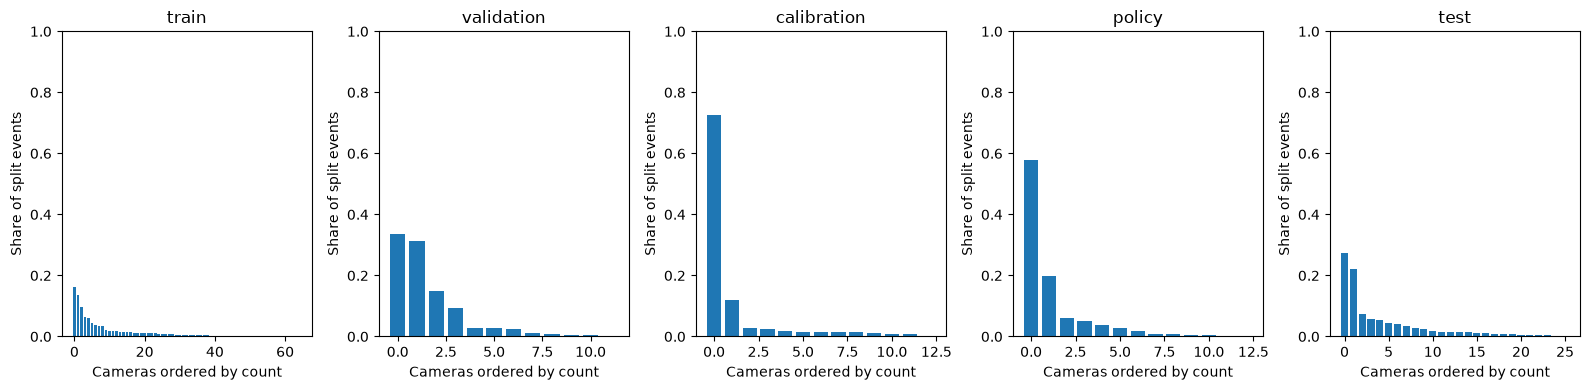

In [3]:
SPLITS=["train","validation","calibration","policy","test"]
camera_counts=manifest.groupby(["split","location"]).size().rename("events").reset_index()
camera_counts["split_share"]=camera_counts.events/camera_counts.groupby("split").events.transform("sum")
camera_counts["small_camera"]=camera_counts.events<CFG["small_camera_flag_below"]
class_camera=manifest.groupby(["split","location","class_name"]).size().rename("events").reset_index()
class_camera["share_within_camera"]=class_camera.events/class_camera.groupby(["split","location"]).events.transform("sum")
class_camera["share_of_category_split"]=class_camera.events/class_camera.groupby(["split","class_name"]).events.transform("sum")
concentration=[];category_concentration=[]
for split in SPLITS:
    g=camera_counts.loc[camera_counts.split.eq(split)].sort_values("events",ascending=False)
    p=g.split_share.to_numpy();concentration.append({"split":split,"events":int(g.events.sum()),
        "represented_cameras":len(g),"largest_camera":g.iloc[0].location,"largest_camera_events":int(g.iloc[0].events),
        "largest_share":float(p[0]),"top_three_share":float(p[:3].sum()),
        "concentration_equivalent_cameras":float(1/(p*p).sum()),
        "small_cameras":int(g.small_camera.sum()),"minimum_events":int(g.events.min()),"maximum_events":int(g.events.max())})
    for name in CLASSES:
        h=class_camera.loc[class_camera.split.eq(split)&class_camera.class_name.eq(name)].sort_values("events",ascending=False)
        category_concentration.append({"split":split,"class":name,"events":int(h.events.sum()),"cameras":len(h),
            "largest_camera":str(h.iloc[0].location) if len(h) else None,
            "largest_camera_share":float(h.iloc[0].share_of_category_split) if len(h) else np.nan})
concentration=table("camera_concentration_by_split.csv",concentration)
table("camera_event_counts.csv",camera_counts)
table("class_camera_counts.csv",class_camera)
table("category_camera_concentration.csv",category_concentration)
class_counts=pd.crosstab(manifest.split,manifest.class_name).reindex(index=SPLITS,columns=CLASSES,fill_value=0)
class_shares=class_counts.div(class_counts.sum(axis=1),axis=0)
table("class_distribution_by_split.csv",class_shares.reset_index())
display(concentration.round(4));display(class_shares.round(4))
fig,axes=plt.subplots(1,5,figsize=(16,4))
for ax,split in zip(axes,SPLITS):
    g=camera_counts.loc[camera_counts.split.eq(split)].sort_values("events",ascending=False)
    ax.bar(np.arange(len(g)),g.split_share)
    ax.set(title=split,xlabel="Cameras ordered by count",ylabel="Share of split events",ylim=(0,1))
fig.tight_layout();fig.savefig(REPORT/"camera_concentration.png",dpi=160);plt.show();plt.close(fig)


## 4. Define weighted metrics and reproduce notebook04
For NLL, Brier and accuracy, equal-camera weighting equals the average of camera-specific metrics. For nonlinear quantities, definitions matter:
- **Equal-camera pooled ECE** applies event weights $1/n_c$ inside the same global confidence bins. It is not the mean of camera ECEs. Opposite within-bin errors at different cameras can cancel.
- **Equal-camera pooled macro-F1** is computed from a camera-weighted confusion matrix, retaining all five categories. It is not the mean of small-camera F1 scores.
- **Equal-camera accepted error** is weighted accepted mistakes divided by weighted accepted events. It describes the accepted population under the equal-camera sampling distribution. It is not the mean of conditional camera errors.

We additionally report the mean per-camera ECE and mean accepted error among cameras with any accepted events as separately labelled diagnostics. Small-camera ECE is noisy and can be biased upward. A camera with zero accepted events has undefined conditional error, not zero.


In [4]:
B=CFG["ece_bins"]
METRICS=["accuracy","nll","brier","ece","macro_f1","coverage","accepted_error"]
def probs(z,T):
    v=np.asarray(z,dtype=float)/float(T);v-=v.max(1,keepdims=True)
    lp=v-np.log(np.exp(v).sum(1,keepdims=True));return np.exp(lp),lp

def camera_statistics(a,T,policy):
    z,y=a["logits"],a["labels"];p,lp=probs(z,T);pred=z.argmax(1)
    correct=pred==y;conf=p.max(1);bins=np.minimum((conf*B).astype(int),B-1)
    accept=np.zeros(len(y),dtype=bool) if policy["threshold"] is None else conf>=policy["threshold"]
    # Additive statistics: n, correct, NLL sum, Brier sum, accepted, accepted wrong,
    # followed by flattened confusion counts and confidence-bin count/confidence/correct sums.
    start=6+K*K;v=np.zeros((len(y),start+3*B))
    v[:,:6]=np.column_stack([np.ones(len(y)),correct,-lp[np.arange(len(y)),y],
                            ((p-np.eye(K)[y])**2).sum(1),accept,accept&~correct])
    v[np.arange(len(y)),6+y*K+pred]=1
    v[np.arange(len(y)),start+bins]=1
    v[np.arange(len(y)),start+B+bins]=conf
    v[np.arange(len(y)),start+2*B+bins]=correct
    agg=np.zeros((C,v.shape[1]));np.add.at(agg,CAM_INDEX,v)
    return agg

def calculate(s):
    s=np.atleast_2d(s);n=s[:,0];cm=s[:,6:6+K*K].reshape(-1,K,K)
    den=cm.sum(1)+cm.sum(2)
    f1=np.divide(2*np.diagonal(cm,axis1=1,axis2=2),den,out=np.zeros_like(den),where=den>0).mean(1)
    start=6+K*K
    ece=np.abs(s[:,start+B:start+2*B]-s[:,start+2*B:start+3*B]).sum(1)/n
    risk=np.divide(s[:,5],s[:,4],out=np.full(len(n),np.nan),where=s[:,4]>0)
    return dict(zip(METRICS,[s[:,1]/n,s[:,2]/n,s[:,3]/n,ece,f1,s[:,4]/n,risk]))

AGG={};per_camera_rows=[];summary_rows=[];diagnostic_rows=[]
for key,a in TEST.items():
    for variant,T in [("raw",1.),("scaled",DEC[key]["temperature"])]:
        agg=camera_statistics(a,T,DEC[key]["policies"][variant]);AGG[(*key,variant)]=agg
        local=calculate(agg)
        for i,cam in enumerate(CAMS):
            mask=CAM_INDEX==i
            per_camera_rows.append({"model":key[0],"seed":key[1],"variant":variant,"location":cam,
                "events":int(agg[i,0]),"true_categories_present":int(test_frame.loc[mask,"class_name"].nunique()),
                "small_camera":bool(agg[i,0]<CFG["small_camera_flag_below"]),
                "accepted":int(agg[i,4]),"accepted_errors":int(agg[i,5]),
                **{m:float(local[m][i]) for m in METRICS if m!="macro_f1"}})
        finite=local["accepted_error"][np.isfinite(local["accepted_error"])]
        diagnostic_rows.append({"model":key[0],"seed":key[1],"variant":variant,
            "mean_within_camera_ece":float(local["ece"].mean()),
            "mean_error_among_accepting_cameras":float(finite.mean()) if len(finite) else np.nan,
            "cameras_with_acceptance":len(finite),"total_cameras":C})
        for weighting,stats in [("image",agg),("equal_camera",agg/N_CAM[:,None])]:
            score={m:float(v[0]) for m,v in calculate(stats.sum(0)).items()}
            summary_rows.append({"model":key[0],"seed":key[1],"variant":variant,"weighting":weighting,**score})
            if weighting=="image":
                old=old_results.loc[old_results.model.eq(key[0])&old_results.seed.eq(key[1])&old_results.variant.eq(variant)]
                assert len(old)==1
                for m in METRICS:
                    assert np.isclose(score[m],float(old.iloc[0][m]),atol=1e-10,equal_nan=True),(key,variant,m)
per_camera=table("test_per_camera.csv",per_camera_rows)
weighted=table("weighting_comparison.csv",summary_rows)
table("within_camera_diagnostics.csv",diagnostic_rows)
means=weighted.groupby(["model","variant","weighting"])[METRICS].agg(lambda s: s.mean() if s.notna().all() else np.nan).reset_index()
table("weighting_seed_means.csv",means)
display(means.round(4))
print("All original notebook04 image-weighted metrics reproduced.")


,model,variant,weighting,accuracy,nll,brier,ece,macro_f1,coverage,accepted_error
0,efficientnet_b0,raw,equal_camera,0.7934,0.5585,0.2796,0.0650,0.8021,0.7959,0.1067
1,efficientnet_b0,raw,image,0.8198,0.4867,0.2406,0.0455,0.7557,0.8179,0.0808
2,efficientnet_b0,scaled,equal_camera,0.7934,0.5223,0.2714,0.0390,0.8021,0.8021,0.1053
3,efficientnet_b0,scaled,image,0.8198,0.4625,0.2350,0.0227,0.7557,0.8174,0.0788
4,mobilenet_v3_large,raw,equal_camera,0.7561,0.6301,0.3185,0.0939,0.7563,0.7612,0.1167
5,mobilenet_v3_large,raw,image,0.8121,0.5113,0.2543,0.0596,0.7285,0.7930,0.0792
6,mobilenet_v3_large,scaled,equal_camera,0.7561,0.5755,0.3023,0.0527,0.7563,0.7670,0.1162
7,mobilenet_v3_large,scaled,image,0.8121,0.4744,0.2437,0.0232,0.7285,0.7955,0.0792


All original notebook04 image-weighted metrics reproduced.


## 5. Is the calibration benefit spread across cameras?
For each model and camera, average the raw-minus-scaled change over all three seeds. Positive NLL/Brier/ECE gain means improvement; negative means deterioration. Count improved, worsened and approximately unchanged cameras, and plot the individual NLL changes. A camera with two events receives the same weight in an equal-camera mean as one with hundreds, but its observed rate is much less stable. The <30-event flag is descriptive, not an exclusion rule or significance threshold.

We also calculate which cameras contribute most to accepted mistakes. High event share and high error rate are different properties: counts and rates must be inspected together. We do not choose a favourable seed or remove difficult cameras.


,model,metric,cameras,improved,worsened,approximately_unchanged,equal_camera_mean_gain
0,mobilenet_v3_large,nll,26,19,7,0,0.0546
1,mobilenet_v3_large,brier,26,21,5,0,0.0162
2,mobilenet_v3_large,ece,26,19,7,0,0.0149
3,efficientnet_b0,nll,26,17,9,0,0.0362
4,efficientnet_b0,brier,26,16,10,0,0.0082
5,efficientnet_b0,ece,26,10,16,0,0.0005


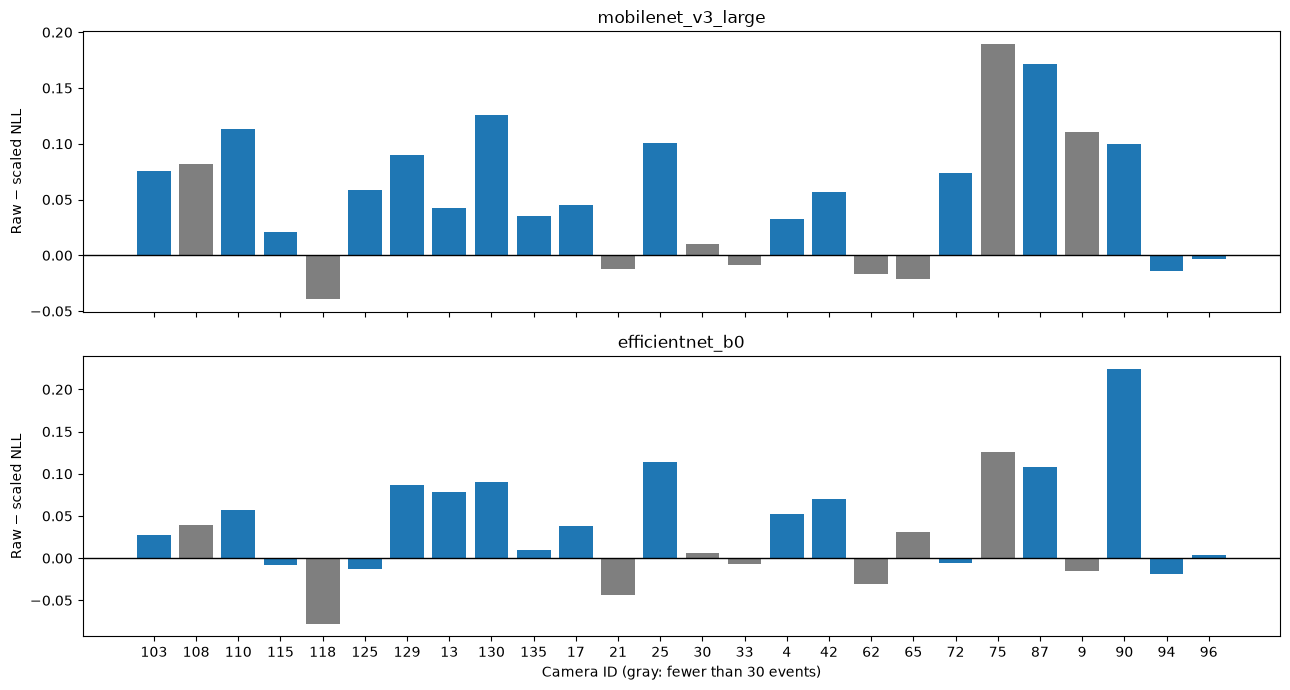

In [5]:
gain_rows=[];benefit_counts=[]
for model in ["mobilenet_v3_large","efficientnet_b0"]:
    part=per_camera.loc[per_camera.model.eq(model)]
    for metric in ["nll","brier","ece"]:
        pairs=part.pivot(index=["seed","location"],columns="variant",values=metric)
        gains=(pairs.raw-pairs.scaled).groupby("location").mean().reindex(CAMS)
        for cam,gain in gains.items():
            n=int(N_CAM[np.where(CAMS==cam)[0][0]])
            gain_rows.append({"model":model,"location":cam,"metric":metric,"mean_seed_gain":float(gain),
                              "events":n,"small_camera":n<CFG["small_camera_flag_below"]})
        benefit_counts.append({"model":model,"metric":metric,"cameras":C,
            "improved":int((gains>1e-10).sum()),"worsened":int((gains< -1e-10).sum()),
            "approximately_unchanged":int((gains.abs()<=1e-10).sum()),
            "equal_camera_mean_gain":float(gains.mean())})
gains_by_camera=table("camera_calibration_gains.csv",gain_rows)
benefit_counts=table("camera_benefit_counts.csv",benefit_counts)
error_counts=per_camera[["model","seed","variant","location","events","accepted","accepted_errors"]].copy()
error_counts["share_of_all_accepted_errors"]=error_counts.accepted_errors/error_counts.groupby(["model","seed","variant"]).accepted_errors.transform("sum").replace(0,np.nan)
table("accepted_error_concentration.csv",error_counts)
display(benefit_counts.round(4))
fig,axes=plt.subplots(2,1,figsize=(13,7),sharex=True)
for ax,model in zip(axes,["mobilenet_v3_large","efficientnet_b0"]):
    g=gains_by_camera.loc[gains_by_camera.model.eq(model)&gains_by_camera.metric.eq("nll")].set_index("location").reindex(CAMS)
    colors=["tab:gray" if small else "tab:blue" for small in g.small_camera]
    ax.bar(range(C),g.mean_seed_gain,color=colors)
    ax.axhline(0,color="black",lw=1);ax.set(title=model,ylabel="Raw − scaled NLL")
axes[-1].set(xticks=range(C),xticklabels=CAMS,xlabel="Camera ID (gray: fewer than 30 events)")
fig.tight_layout();fig.savefig(REPORT/"nll_gains_by_camera.png",dpi=160);plt.show();plt.close(fig)


## 6. Paired camera bootstrap: weightings and direct difference in gains
All comparisons use the same resampled camera multiplicities for both architectures, all seeds and both variants. For image weighting, sum the sampled cameras' event statistics. For equal-camera weighting, first divide each camera's statistics by its event count; sum those normalized statistics with the same multiplicities. Thus an included camera has equal total weight per occurrence.

Within each bootstrap draw, compute the metric for each trained run and average over the three fixed seeds. For loss metric $L$:

$$G_m=L_{m,raw}-L_{m,scaled},\qquad D=G_{EfficientNet}-G_{MobileNet}.$$

$G_m>0$ indicates calibration improvement. $D>0$ means EfficientNet improved more; $D<0$ means MobileNet improved more. The paired percentile interval for $D$ directly addresses the proposal's architectural difference question. Separate intervals showing improvement for both models do not establish a difference between their improvements. A model with lower final NLL need not have the larger gain.

We report intervals for seed-averaged metrics and gains under both weighting schemes. These condition on trained models, calibration/policy fitting and one test-camera split. They do not estimate refitting uncertainty or correct detector overlap, small calibration-camera diversity, or selection optimism. Twenty-six observed cameras are a limited basis for generalization. Intervals for ECE remain bin-dependent. No p-values or multiple-testing-adjusted claims are produced.


In [6]:
rng=np.random.default_rng(CFG["bootstrap_seed"])
W=rng.multinomial(C,np.full(C,1/C),size=CFG["bootstrap_repeats"]).astype(float)
BOOT={};interval_rows=[];contrast_rows=[]
def interval(v):
    finite=np.asarray(v)[np.isfinite(v)]
    if not len(finite):return np.nan,np.nan,0
    return float(np.quantile(finite,.025)),float(np.quantile(finite,.975)),len(finite)
def point(model,variant,weighting,metric):
    x=weighted.loc[weighted.model.eq(model)&weighted.variant.eq(variant)&weighted.weighting.eq(weighting),metric]
    assert len(x)==3
    return float(x.mean()) if x.notna().all() else np.nan
for key,agg in AGG.items():
    for weighting,stats in [("image",agg),("equal_camera",agg/N_CAM[:,None])]:
        BOOT[(*key,weighting)]=calculate(W@stats)
# Average across all three seeds; undefined risks remain undefined (no silent seed dropping).
SEED_BOOT={}
for model in ["mobilenet_v3_large","efficientnet_b0"]:
    for variant in ["raw","scaled"]:
        for weighting in ["image","equal_camera"]:
            for metric in METRICS:
                v=np.mean(np.stack([BOOT[(model,s,variant,weighting)][metric] for s in [42,123,2026]]),axis=0)
                SEED_BOOT[(model,variant,weighting,metric)]=v
                lo,hi,valid=interval(v)
                interval_rows.append({"model":model,"variant":variant,"weighting":weighting,"metric":metric,
                    "estimate":point(model,variant,weighting,metric),"ci_low":lo,"ci_high":hi,
                    "valid_replicates":valid,"total_replicates":len(W)})
for weighting in ["image","equal_camera"]:
    for metric in ["nll","brier","ece"]:
        gains={};gain_points={}
        for model in ["mobilenet_v3_large","efficientnet_b0"]:
            gains[model]=SEED_BOOT[(model,"raw",weighting,metric)]-SEED_BOOT[(model,"scaled",weighting,metric)]
            gain_points[model]=point(model,"raw",weighting,metric)-point(model,"scaled",weighting,metric)
            lo,hi,valid=interval(gains[model])
            contrast_rows.append({"comparison":model+" calibration gain (raw minus scaled)","weighting":weighting,
                "metric":metric,"estimate":gain_points[model],"ci_low":lo,"ci_high":hi,
                "valid_replicates":valid,"total_replicates":len(W)})
        difference=gains["efficientnet_b0"]-gains["mobilenet_v3_large"]
        lo,hi,valid=interval(difference)
        contrast_rows.append({"comparison":"EfficientNet gain minus MobileNet gain","weighting":weighting,
            "metric":metric,"estimate":gain_points["efficientnet_b0"]-gain_points["mobilenet_v3_large"],
            "ci_low":lo,"ci_high":hi,"valid_replicates":valid,"total_replicates":len(W)})
intervals=table("weighted_camera_bootstrap_intervals.csv",interval_rows)
contrasts=table("calibration_gain_contrasts.csv",contrast_rows)
display(contrasts.round(5))
# Algebra checks: equal-camera NLL gain is the mean of per-camera NLL gains.
for model in ["mobilenet_v3_large","efficientnet_b0"]:
    direct=gains_by_camera.loc[gains_by_camera.model.eq(model)&gains_by_camera.metric.eq("nll"),"mean_seed_gain"].mean()
    assert np.isclose(direct,point(model,"raw","equal_camera","nll")-point(model,"scaled","equal_camera","nll"))


,comparison,weighting,metric,estimate,ci_low,ci_high,valid_replicates,total_replicates
0,mobilenet_v3_large calibration gain (raw minus...,image,nll,0.03687,0.01687,0.07475,2000,2000
1,efficientnet_b0 calibration gain (raw minus sc...,image,nll,0.02424,0.00774,0.05907,2000,2000
2,EfficientNet gain minus MobileNet gain,image,nll,-0.01262,-0.02911,0.00208,2000,2000
3,mobilenet_v3_large calibration gain (raw minus...,image,brier,0.01058,0.00411,0.02295,2000,2000
4,efficientnet_b0 calibration gain (raw minus sc...,image,brier,0.00565,0.00146,0.01536,2000,2000
5,EfficientNet gain minus MobileNet gain,image,brier,-0.00493,-0.01039,-0.00043,2000,2000
6,mobilenet_v3_large calibration gain (raw minus...,image,ece,0.03636,0.01296,0.05045,2000,2000
7,efficientnet_b0 calibration gain (raw minus sc...,image,ece,0.02284,0.00091,0.03843,2000,2000
8,EfficientNet gain minus MobileNet gain,image,ece,-0.01352,-0.02609,-0.00235,2000,2000
9,mobilenet_v3_large calibration gain (raw minus...,equal_camera,nll,0.05457,0.03163,0.07763,2000,2000


## 7. Influence of individual test cameras
Leave-one-camera-out analysis recalculates the mean-seed NLL gain with each camera omitted in turn, using the original fixed predictions and decisions. This is an influence diagnostic, not retraining, refitting, a new split search, or justification to discard locations. Compare the range of these gains and whether their direction changes. A conclusion that changes on omitting one camera is sensitive to that observed location.

This cannot tell us whether excluding a calibration camera would change the temperature. That would be a distinct refitting experiment. We deliberately keep the original fitting procedure fixed here.


,model,weighting,minimum_gain,maximum_gain,full_test_gain
0,efficientnet_b0,equal_camera,0.02871,0.04079,0.03623
1,efficientnet_b0,image,0.02153,0.03355,0.02424
2,mobilenet_v3_large,equal_camera,0.04918,0.05832,0.05457
3,mobilenet_v3_large,image,0.03320,0.05204,0.03687


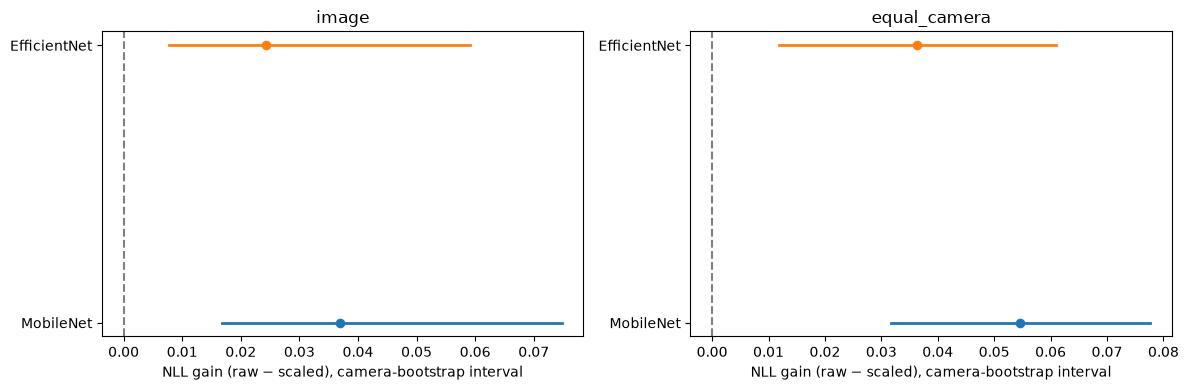

In [7]:
loo_rows=[]
for weighting in ["image","equal_camera"]:
    for model in ["mobilenet_v3_large","efficientnet_b0"]:
        for i,cam in enumerate(CAMS):
            local={}
            for variant in ["raw","scaled"]:
                values=[]
                for seed in [42,123,2026]:
                    a=AGG[(model,seed,variant)]
                    stats=a if weighting=="image" else a/N_CAM[:,None]
                    values.append(float(calculate(stats.sum(0)-stats[i])["nll"][0]))
                local[variant]=float(np.mean(values))
            loo_rows.append({"model":model,"weighting":weighting,"omitted_camera":cam,
                "omitted_events":int(N_CAM[i]),"nll_gain":local["raw"]-local["scaled"],
                "full_test_nll_gain":point(model,"raw",weighting,"nll")-point(model,"scaled",weighting,"nll")})
loo=table("leave_one_camera_out_nll_gains.csv",loo_rows)
loo_summary=loo.groupby(["model","weighting"]).agg(minimum_gain=("nll_gain","min"),
    maximum_gain=("nll_gain","max"),full_test_gain=("full_test_nll_gain","first")).reset_index()
table("leave_one_camera_out_summary.csv",loo_summary)
display(loo_summary.round(5))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,weighting in zip(axes,["image","equal_camera"]):
    for i,model in enumerate(["mobilenet_v3_large","efficientnet_b0"]):
        r=contrasts.loc[contrasts.weighting.eq(weighting)&contrasts.metric.eq("nll")&contrasts.comparison.eq(model+" calibration gain (raw minus scaled)")].iloc[0]
        ax.plot([r.ci_low,r.ci_high],[i,i],lw=2)
        ax.scatter([r.estimate],[i],s=35)
    ax.axvline(0,color="gray",ls="--")
    ax.set(title=weighting,yticks=[0,1],yticklabels=["MobileNet","EfficientNet"],xlabel="NLL gain (raw − scaled), camera-bootstrap interval")
fig.tight_layout();fig.savefig(REPORT/"nll_gains_by_weighting.png",dpi=160);plt.show();plt.close(fig)


## 8. Write the report handoff from actual audit results
The handoff records representation, weighting comparisons, benefit counts, interaction intervals and influence diagnostics. It also generates a conservative reading of the primary NLL intervals. A zero-crossing interval is inconclusive, not evidence that the methods are equivalent. An interval excluding zero is conditional evidence under the stated audit assumptions, not universal architectural superiority.

The proposal's H1 combines improvement and an architectural difference. Support for improvement alone is partial support, not confirmation of the full compound hypothesis. Keep the original 5% policy-target failures in the report regardless of the audit results. This notebook does not revise those thresholds or claim that camera imbalance caused their failure.


In [8]:
def plain(df):return "```text\n"+df.to_string(index=False,float_format=lambda x:f"{x:.5f}")+"\n```"
interpretations=[]
for r in contrasts.loc[contrasts.metric.eq("nll")].itertuples(index=False):
    if r.comparison=="EfficientNet gain minus MobileNet gain":
        finding=("the interval favours a larger EfficientNet NLL gain" if r.ci_low>0 else
                 "the interval favours a larger MobileNet NLL gain" if r.ci_high<0 else
                 "the interval includes zero; an architectural difference in NLL gain is inconclusive")
    else:
        finding=("the interval supports an NLL reduction" if r.ci_low>0 else
                 "the interval supports NLL deterioration" if r.ci_high<0 else
                 "the interval includes zero; the direction of NLL change is inconclusive")
    interpretations.append(f"- {r.weighting}, {r.comparison}: {finding} (estimate {r.estimate:.5f}; interval [{r.ci_low:.5f}, {r.ci_high:.5f}]).")
notes=f"""# Camera audit and direct calibration-gain comparison
Generated {now()}. Parent evaluation hash: {completion['evaluation_sha256']}.

## Status and relation to the proposal
This is a post hoc sensitivity analysis after reviewing notebook04 test results and finding camera concentration. The original trained models, fine-tuning checkpoint-selection rule, temperatures, policies and test set were retained. No retraining, new image processing, calibration refitting, threshold changes or new test inference occurred. NLL is the primary metric of this additional audit; the proposal did not predefine one. All models and seeds were retained. Both weighting schemes must be reported rather than selecting a favourable one.

## Camera representation
{plain(concentration)}
Concentration-equivalent cameras is 1/sum(event_share^2), a count-concentration descriptor, not an effective independent sample size. Selected events are not necessarily independent animals. Calibration/policy fitting remains image-weighted as in notebook04; this audit diagnoses but does not repair their concentration. Per-camera tables and class-camera counts provide the full detail.

## Category distribution by split
{plain(class_shares.reset_index())}
Differences in class composition and camera conditions may affect calibration and policy transfer. This observational audit does not identify their causal contributions or demonstrate background shortcuts.

## Original metrics reproduced and weightings compared (mean three seeds)
{plain(means)}
Image weighting describes the observed event mixture; equal-camera weighting describes drawing a camera uniformly and an event uniformly within it. Equal-camera NLL/Brier/accuracy are means of camera-specific metrics. Equal-camera pooled ECE/F1 use camera-normalized event statistics before computing the nonlinear metric. Weighted accepted error is weighted mistakes divided by weighted accepted events, not the average conditional error of accepting cameras. The latter and mean within-camera ECE are separately labelled diagnostics. Undefined conditional errors remain blank.

## Spread of benefit across test cameras
{plain(benefit_counts)}
Counts of improved cameras are descriptive, not independent hypothesis tests; very small camera samples are noisy. No camera is excluded using the <30-event flag. Camera IDs denote dataset locations, not verified spatial distances or independent habitats.

## Paired comparisons of calibration gains
{plain(contrasts)}
For losses, gain=raw minus scaled. Interaction=EfficientNet gain minus MobileNet gain. Positive interaction favours a larger EfficientNet improvement; negative favours MobileNet. This compares changes directly, unlike comparing final calibrated scores or separate significance assessments.

### Primary NLL reading
{chr(10).join(interpretations)}

## Influence of individual test cameras
{plain(loo_summary)}
Each omitted-camera diagnostic uses fixed predictions and rules. Do not discard cameras based on these outcomes or describe the exercise as a fresh independent evaluation.

## Uncertainty and limitations
2,000 paired whole-camera bootstrap draws, seed {CFG['bootstrap_seed']}, recompute both weightings with shared camera multiplicities across architectures, variants and seeds. Three seed-specific scores are averaged within every draw. The intervals condition on the fitted models, calibration/policy decisions and one available test split. They exclude uncertainty from refitting, alternative splits or detector pretraining, and are exploratory/unadjusted across multiple outcomes. ECE is bin-dependent; per-camera ECE is especially unstable with small n. Global weighted ECE can hide local miscalibration. Equal-camera weighting increases the influence of sparsely observed sites. A zero-crossing interaction interval does not establish equivalence or justify accepting the full compound H1. The original failure to meet the 5% test acceptance-error target remains part of the result.

MegaDetector inputs used official precomputed MDv5a predictions with known historical Caltech training overlap; classifier camera holdout does not guarantee detector holdout. Class-specific generalization, restricted categories, event sampling and the fine-tuning-only checkpoint rule remain limitations documented in notebook04.

## Files to use
camera_concentration_by_split.csv; camera_event_counts.csv; category_camera_concentration.csv; class_camera_counts.csv; test_per_camera.csv; weighting_seed_means.csv; weighted_camera_bootstrap_intervals.csv; camera_benefit_counts.csv; calibration_gain_contrasts.csv; leave_one_camera_out_summary.csv. Detailed supporting tables and three figures are in this audit folder. Notebook04 outputs remain unchanged.

## Method references
Project proposal, ML_project_notes.pdf, Group 8: calibration comparison at unseen camera locations.
Guo et al. (2017), On Calibration of Modern Neural Networks: https://proceedings.mlr.press/v70/guo17a.html
Use with the original notebook04 methods and references; equal-camera weighting and this audit are project-defined sensitivity analyses, not claimed replications of Dussert et al.
"""
write(REPORT/"CAMERA_AUDIT_METHODS_AND_RESULTS.md",notes)
# Verify the original evaluation is unchanged after analysis.
for name,expected in completion["outputs"].items():assert sha(PREVIOUS/name)==expected
write(REPORT/"completion.json",jtext({"time_utc":now(),"audit_protocol_sha256":sha(REPORT/"audit_protocol.json"),
    "parent_evaluation_sha256":completion["evaluation_sha256"],"test_cameras":C,"runs":len(TEST),
    "original_evaluation_unchanged":True,"refitting_performed":False,
    "outputs":{p.name:sha(p) for p in sorted(REPORT.iterdir()) if p.is_file() and p.name!="completion.json"}}))
print("Audit complete:",REPORT)
print("Original evaluation unchanged. Save this executed notebook with Ctrl+S.")
print("Share camera_concentration_by_split.csv, weighting_seed_means.csv, camera_benefit_counts.csv and calibration_gain_contrasts.csv.")


Audit complete: /home/fia/Schreibtisch/ml_project_final/wildlife_confidence_project/reports/five_categories_v1/camera_audit_v1
Original evaluation unchanged. Save this executed notebook with Ctrl+S.
Share camera_concentration_by_split.csv, weighting_seed_means.csv, camera_benefit_counts.csv and calibration_gain_contrasts.csv.
